# Découpage imposé par l'énoncé

L'énoncé demande : **les 2000 premiers cycles pour construire le modèle, les 205 derniers comme échantillon de test final**.

Jusqu'ici, les notebooks d'exploration mélangeaient les cycles puis gardaient 20 % au hasard pour le test. Ce notebook refait les 4 jeux de features avec le bon découpage et mesure ce que ça change.

Trois différences avec les notebooks d'exploration :

1. **Pas de mélange** : train = cycles 0 à 1999, test = cycles 2000 à 2204.
2. **Sélection des features sur le train seulement** : les colonnes constantes ou corrélées sont choisies en regardant uniquement les 2000 premiers cycles, puis on garde les mêmes colonnes dans le test.
3. **Bornes des histogrammes fixées sur le train seulement** : le test ne doit rien influencer.

Ainsi, le test se comporte comme de vrais cycles futurs, jamais vus pendant la construction du modèle.

## 1. Chargement

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (load_data, save_data, load_processed, save_figure, make_binary_target,
                       class_distribution, build_feature_set, split_first_n, select_features,
                       FEATURE_SETS)
from src.model import get_baseline_models, get_ensemble_models
from src.train import compare_models

warnings.filterwarnings("ignore")

PS2 = load_data("data/raw/PS2.txt")
FS1 = load_data("data/raw/FS1.txt")
profile = load_data("data/raw/profile.txt")
profile.columns = ["cooler", "valve", "pump", "accumulator", "stable"]

y = make_binary_target(profile["valve"], positive_value=100, name="valve_optimal")

## 2. Les 205 derniers cycles ne ressemblent pas aux 2000 premiers

Les cycles sont rangés dans l'ordre des expériences. Les derniers ont donc été enregistrés dans des conditions particulières. On compare, pour chaque composant du système, la répartition de ses états dans le train et dans le test.

In [2]:
# Pourcentage de cycles dans chaque état, pour chaque composant
partie = pd.Series(["train (2000 premiers)"] * 2000 + ["test (205 derniers)"] * 205, index=profile.index)

for composant in profile.columns:
    table = pd.crosstab(profile[composant], partie, normalize="columns").mul(100).round(1)
    print(f"--- {composant} (%)")
    print(table[["train (2000 premiers)", "test (205 derniers)"]], end="\n\n")

--- cooler (%)
col_0   train (2000 premiers)  test (205 derniers)
cooler                                            
3                        36.6                  0.0
20                       36.6                  0.0
100                      26.8                100.0

--- valve (%)
col_0  train (2000 premiers)  test (205 derniers)
valve                                            
73                      16.0                 19.5
80                      15.9                 20.5
90                      15.5                 24.4
100                     52.6                 35.6

--- pump (%)
col_0  train (2000 premiers)  test (205 derniers)
pump                                             
0                       56.0                 49.3
1                       21.4                 30.7
2                       22.6                 20.0

--- accumulator (%)
col_0        train (2000 premiers)  test (205 derniers)
accumulator                                            
90                

In [3]:
pd.concat({"train": class_distribution(y[:2000]), "test": class_distribution(y[2000:])}, axis=1)

train       test      
                  n     %    n     %
valve_optimal                       
0               948  47.4  132  64.4
1              1052  52.6   73  35.6

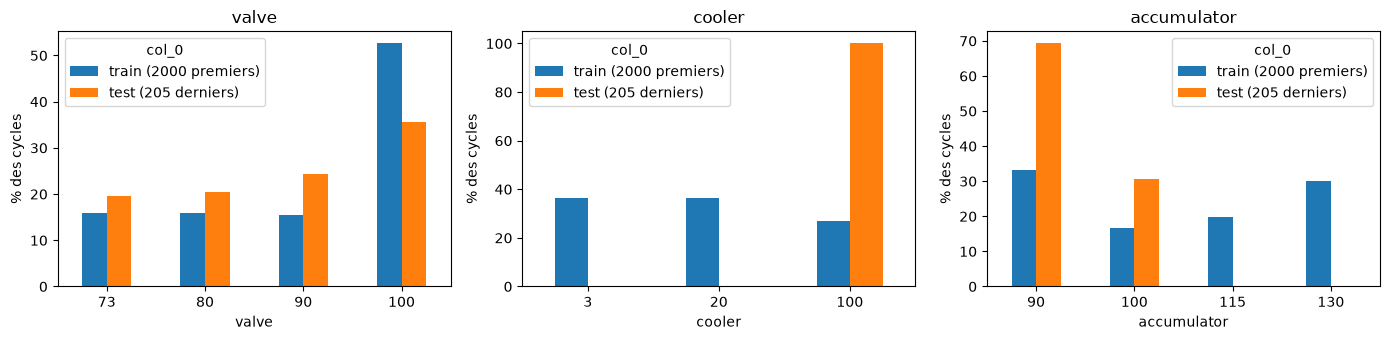

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, composant in zip(axes, ["valve", "cooler", "accumulator"]):
    pd.crosstab(profile[composant], partie, normalize="columns")[
        ["train (2000 premiers)", "test (205 derniers)"]].mul(100).plot.bar(ax=ax, rot=0)
    ax.set_title(composant)
    ax.set_ylabel("% des cycles")
save_figure("decalage_train_test_enonce.png")
plt.show()

**Ce qu'on observe :**

- **Vanne** : le test contient 36 % de vannes optimales contre 53 % dans le train. Le test est plus riche en vannes dégradées.
- **Refroidisseur** : dans le test, il est toujours à 100 %. Dans le train, il est à 100 % dans seulement 27 % des cycles.
- **Accumulateur** : dans le test, il ne prend que 2 des 4 valeurs vues dans le train.
- **Stabilité** : presque tous les cycles du test sont marqués comme non stables.

C'est un **décalage de distribution** : le modèle sera évalué dans des conditions un peu différentes de celles où il a appris. C'est plus exigeant qu'un découpage aléatoire, mais c'est aussi plus proche de la réalité : une usine fait tourner ses machines dans de nouvelles conditions au fil du temps.

Conséquence attendue : les scores sur le test seront plus bas que ceux de la validation croisée sur le train.

## 3. Construction des 4 jeux

Pour chaque méthode : features brutes, découpage 2000 / 205, sélection sur le train, puis sauvegarde dans `data/processed/<nom>_enonce/`.

In [5]:
for nom in FEATURE_SETS:
    X = build_feature_set(nom, PS2, FS1, n_fit=2000)       # bornes des histogrammes : train seulement
    x_train, x_test, y_train, y_test = split_first_n(X, y, n_train=2000)
    x_train, x_test, supprimees = select_features(x_train, x_test)
    save_data(x_train, x_test, y_train, y_test, name=f"{nom}_enonce")
    print(f"{nom:14s} {X.shape[1]:3d} features brutes -> {x_train.shape[1]:2d} gardées : {list(x_train.columns)}")

stats           23 features brutes ->  7 gardées : ['ps2_max', 'ps2_mean', 'ps2_median', 'ps2_q25', 'fs1_max', 'fs1_q75', 'fs1_kurtosis']


spectre          8 features brutes ->  3 gardées : ['ps2_amplitude', 'ps2_centroide', 'fs1_centroide']


stats_spectre   30 features brutes ->  9 gardées : ['ps2_max', 'ps2_mean', 'ps2_median', 'ps2_q25', 'fs1_max', 'fs1_q75', 'fs1_kurtosis', 'ps2_centroide', 'fs1_centroide']


histogramme     40 features brutes -> 14 gardées : ['ps2_bin_0', 'ps2_bin_13', 'ps2_bin_14', 'ps2_bin_15', 'ps2_bin_16', 'fs1_bin_0', 'fs1_bin_4', 'fs1_bin_5', 'fs1_bin_6', 'fs1_bin_8', 'fs1_bin_9', 'fs1_bin_10', 'fs1_bin_11', 'fs1_bin_12']


Les features gardées sont les mêmes que dans les notebooks d'exploration : la sélection ne dépendait pas du découpage. Seules les lignes changent de côté.

## 4. Comparaison des modèles

Mêmes modèles que dans `ensemble_learning.ipynb` (modèles simples et modèles d'ensemble, réglages par défaut), sur les 4 jeux avec le découpage de l'énoncé.

In [6]:
def tous_les_modeles():
    simples = get_baseline_models()
    simples.pop("random_forest")          # déjà présent dans les ensembles
    return {**simples, **get_ensemble_models()}

resultats = {}
for nom in FEATURE_SETS:
    x_train, x_test, y_train, y_test = load_processed(f"{nom}_enonce")
    resultats[nom], _ = compare_models(tous_les_modeles(), x_train, y_train, x_test, y_test)

f1_test = pd.DataFrame({nom: res["f1_macro"] for nom, res in resultats.items()})
f1_test.sort_values("histogramme", ascending=False).round(3)

,stats,spectre,stats_spectre,histogramme
model,,,,
gradient_boosting,0.948,0.943,0.938,0.974
adaboost,0.792,0.933,0.892,0.969
decision_tree,0.923,0.908,0.873,0.953
bagging,0.835,0.928,0.933,0.953
random_forest,0.928,0.953,0.917,0.953
extra_trees,0.879,0.895,0.898,0.943
stacking,0.794,0.933,0.878,0.943
logistic_regression,0.523,0.621,0.861,0.943
svm,0.534,0.874,0.878,0.943


Écart entre la validation croisée (sur le train) et le test, pour le jeu histogramme :

In [7]:
res = resultats["histogramme"]
pd.DataFrame({"cv_f1_macro": res["cv_f1_macro"], "test_f1_macro": res["f1_macro"],
              "écart": res["cv_f1_macro"] - res["f1_macro"]}).round(3)

,cv_f1_macro,test_f1_macro,écart
model,,,
gradient_boosting,0.997,0.974,0.024
adaboost,0.997,0.969,0.028
decision_tree,0.995,0.953,0.042
bagging,0.996,0.953,0.043
random_forest,0.998,0.953,0.045
extra_trees,0.996,0.943,0.053
logistic_regression,0.988,0.943,0.045
svm,0.982,0.943,0.039
stacking,0.992,0.943,0.049


## 5. Découpage aléatoire contre découpage de l'énoncé

Meilleur F1 macro sur le test pour chaque jeu, avec les deux découpages.

In [8]:
f1_aleatoire = {}
for nom in FEATURE_SETS:
    x_train, x_test, y_train, y_test = load_processed(nom)
    res, _ = compare_models(tous_les_modeles(), x_train, y_train, x_test, y_test)
    f1_aleatoire[nom] = res["f1_macro"]
f1_aleatoire = pd.DataFrame(f1_aleatoire)

pd.DataFrame({
    "aléatoire : meilleur F1": f1_aleatoire.max(),
    "aléatoire : modèle": f1_aleatoire.idxmax(),
    "énoncé : meilleur F1": f1_test.max(),
    "énoncé : modèle": f1_test.idxmax(),
}).round(3)

,aléatoire : meilleur F1,aléatoire : modèle,énoncé : meilleur F1,énoncé : modèle
stats,0.984,extra_trees,0.948,gradient_boosting
spectre,0.977,extra_trees,0.953,random_forest
stats_spectre,0.991,extra_trees,0.938,gradient_boosting
histogramme,1.000,adaboost,0.974,gradient_boosting


## 6. Conclusion

**1. Le découpage de l'énoncé est plus exigeant.** Le meilleur F1 macro passe de 0.98 à 1.00 (découpage aléatoire) à 0.94 à 0.97 (découpage de l'énoncé). Le test contient des conditions de fonctionnement peu ou pas vues pendant l'apprentissage : refroidisseur toujours à 100 %, accumulateur réduit à 2 états, plus de vannes dégradées.

**2. La validation croisée sur le train est trop optimiste.** Tous les modèles perdent entre 2 et 12 points entre la validation croisée et le test. Elle reste utile pour **classer** les modèles entre eux, mais pas pour annoncer le score final : seul le test le donne.

**3. Le classement change.** Avec le découpage aléatoire, presque tous les modèles à base d'arbres étaient à égalité. Ici, le **gradient boosting** se détache : meilleur F1 sur 3 jeux sur 4, et plus petit écart entre la validation et le test (0.024 sur `histogramme`). Il résiste le mieux au changement de conditions.

**4. Le jeu `histogramme` reste le meilleur**, quel que soit le découpage. Les modèles linéaires (régression logistique, SVM) y atteignent 0.943, alors qu'ils s'effondrent sur `stats` (environ 0.53) : les histogrammes rendent le problème presque linéaire.

**Décision** : le notebook final utilise le découpage de l'énoncé, le jeu `histogramme` et compare les modèles optimisés, avec le gradient boosting comme favori.